# Mental Health FAQ — NLP Chatbot

In this project, we explore the Mental Health FAQ for Chatbot dataset from [Kaggle](https://www.kaggle.com/datasets/narendrageek/mental-health-faq-for-chatbot/data), which contains 98 question-answer pairs covering a wide range of mental health topics, from general definitions to specific disorders and treatment options. 

The acknowledgements regarding the dataset are:
https://www.thekimfoundation.org/faqs/, 
https://www.mhanational.org/frequently-asked-questions, 
https://www.wellnessinmind.org/frequently-asked-questions/, and 
https://www.heretohelp.bc.ca/questions-and-answers.

In [95]:
import numpy as np 
import pandas as pd 

# Running these lines will list all files under the input directory
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/narendrageek/mental-health-faq-for-chatbot/Mental_Health_FAQ.csv


## Data Loading & Exploratory Data Analysis (EDA)

In [96]:
# Load dataset
df = pd.read_csv("/kaggle/input/datasets/narendrageek/mental-health-faq-for-chatbot/Mental_Health_FAQ.csv")

print(df.head())
print(df.info())

   Question_ID                                          Questions  \
0      1590140        What does it mean to have a mental illness?   
1      2110618                    Who does mental illness affect?   
2      6361820                        What causes mental illness?   
3      9434130  What are some of the warning signs of mental i...   
4      7657263            Can people with mental illness recover?   

                                             Answers  
0  Mental illnesses are health conditions that di...  
1  It is estimated that mental illness affects 1 ...  
2  It is estimated that mental illness affects 1 ...  
3  Symptoms of mental health disorders vary depen...  
4  When healing from mental illness, early identi...  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Question_ID  98 non-null     int64 
 1   Questions    98 non-null 

The command df.info() already told us that there are no null-values. In alternative one can use df.isnull().sum().

In [97]:
# Isolate the feature 'Questions' and target 'Answers', dropping the 'Question_ID' column
df = df[['Questions', 'Answers']]
df.head()

,Questions,Answers
0,What does it mean to have a mental illness?,Mental illnesses are health conditions that di...
1,Who does mental illness affect?,It is estimated that mental illness affects 1 ...
2,What causes mental illness?,It is estimated that mental illness affects 1 ...
3,What are some of the warning signs of mental i...,Symptoms of mental health disorders vary depen...
4,Can people with mental illness recover?,"When healing from mental illness, early identi..."


In [98]:
# Check the total number of duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

In [99]:
# We now check the length of the questions and answers
print(df['Questions'].apply(lambda x: len(x.split())).describe())
print(df['Answers'].apply(lambda x: len(x.split())).describe())

count    98.000000
mean      9.306122
std       4.667077
min       3.000000
25%       6.000000
50%       9.000000
75%      11.000000
max      39.000000
Name: Questions, dtype: float64
count      98.000000
mean      257.142857
std       227.368451
min        16.000000
25%        84.250000
50%       193.500000
75%       388.750000
max      1441.000000
Name: Answers, dtype: float64


In [100]:
# To get an idea if the texts are well-written or with errors
print(df['Questions'].sample(10))

# Missing ? values
print(df['Questions'].str.endswith('?').value_counts())

# Only 1 missing, we check which one exactly
print(df[~df['Questions'].str.endswith('?')])
print(df[~df['Questions'].str.endswith('?')]['Questions'].values[0])


69    Someone I love has been diagnosed with schizop...
75    What’s the difference between anxiety and an a...
76    What's the difference between anxiety and stress?
81    Where can I find information and help for bord...
83             What is antisocial personality disorder?
78    What is dysthymia or persistent depressive dis...
39    How can I reframe the situation and find more ...
93              How do I know if I'm drinking too much?
43                        How can I see a psychiatrist?
46                      How can I find a support group?
Name: Questions, dtype: object
Questions
True     97
False     1
Name: count, dtype: int64
                         Questions  \
16  Where can I go to find therapy   

                                              Answers  
16  Different kinds of therapy are more effective ...  
Where can I go to find therapy


In [101]:
# Since it is only one, we correct it
df.loc[16, 'Questions'] = "Where can I go to find therapy?"

## Word Cloud 

We create a Word Cloud to get an overview of the most frequent words used in the questions.

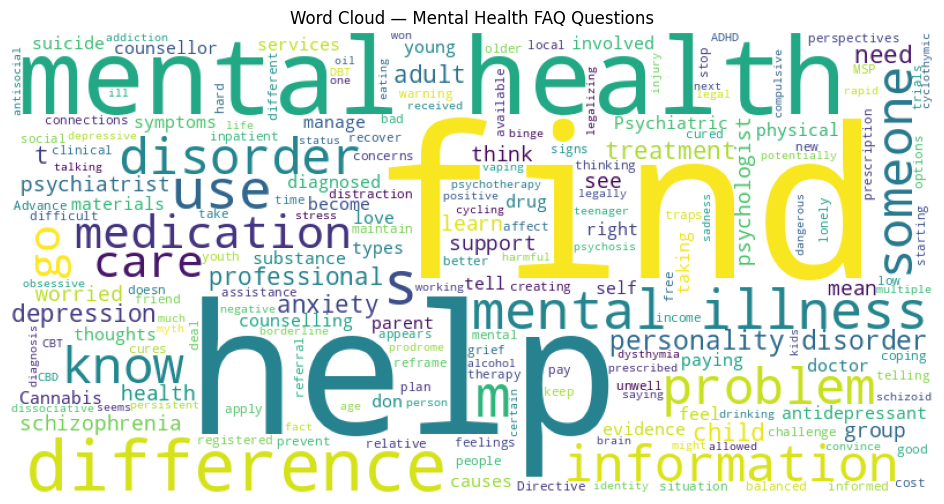

In [102]:
# We now create a Word Cloud to visualize which words appear more 

from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = ' '.join(df['Questions'])
wc = WordCloud(width=800, height=400, background_color='white').generate(text)

plt.figure(figsize=(14,6))
plt.imshow(wc)
plt.axis('off')
plt.title('Word Cloud — Mental Health FAQ Questions')
plt.show()

## BERT-style transformer

We use Sentence-BERT, a BERT-style transformer model pre-trained on large text corpora, to encode each question into a dense 384-dimensional vector that captures its semantic meaning. These embeddings are then normalized to ensure consistent cosine similarity computation.

In [103]:
from sentence_transformers import SentenceTransformer

# Download the pre-trained model from HuggingFace
sbert = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
embeddings = sbert.encode(df['Questions'].tolist(), show_progress_bar=True)

print(embeddings.shape)

from sklearn.preprocessing import normalize

# Normalization 
embeddings_norm = normalize(embeddings)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

(98, 384)


## Clustering procedure

To determine the optimal number of clusters, we apply the so-called Elbow Method: we run K-Means for different values of K and plot the result.

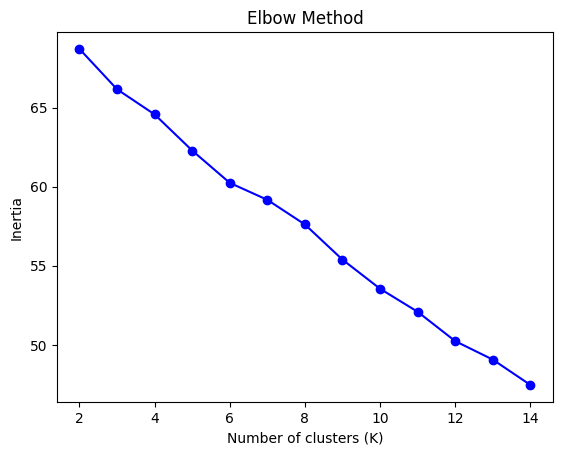

In [104]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
K_range = range(2, 15)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(embeddings)
    inertias.append(km.inertia_)

plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

The Elbow Method does not show a clear inflection point (elbow), which is common with small datasets (only 98 data). However, the curve starts to flatten around K=5 or K=6, suggesting that adding more clusters beyond this point yields diminishing returns. We proceed with K=8 as a reasonable trade-off.

In [105]:
# Applying K-Means clustering with K=8
km = KMeans(n_clusters=8, random_state=42)
df['cluster'] = km.fit_predict(embeddings)

df['cluster'].value_counts()

cluster
1    24
6    21
2    14
5    10
3     9
4     8
7     6
0     6
Name: count, dtype: int64

In [106]:
# Inspecting cluster contents
for i in range(8):
    print(f"\n--- Cluster {i} ---")
    print(df[df['cluster'] == i]['Questions'].values)


--- Cluster 0 ---
['How do I know if I’m unwell?'
 'What should I do if I’m worried about a friend or relative?'
 'How can I maintain social connections? What if I feel lonely?'
 'How can I use distraction to manage difficult thoughts or feelings?'
 'How can I manage grief?' "How do I know if I'm drinking too much?"]

--- Cluster 1 ---
['What does it mean to have a mental illness?'
 'Who does mental illness affect?' 'What causes mental illness?'
 'What are some of the warning signs of mental illness?'
 'Can people with mental illness recover?'
 'What should I do if I know someone who appears to have the symptoms of a mental disorder?'
 'What is the difference between mental health professionals?'
 'What are the different types of mental health professionals?'
 'What is mental health?' 'Can you prevent mental health problems?'
 'Are there cures for mental health problems?'
 'What causes mental health problems?'
 "What's the difference between a psychiatrist and a registered psychologis

In [107]:
# We manually assign labels to clusters, after inspecting the questions in each cluster
cluster_names = {
    0: 'Coping & Wellbeing',
    1: 'Mental Health General Knowledge',
    2: 'Treatment Options',
    3: 'Specific Disorders Definitions',
    4: 'Support & Self-Management',
    5: 'Helping Someone & Personal Concerns',
    6: 'Finding Help & Resources',
    7: 'Medication'
}

df['topic'] = df['cluster'].map(cluster_names)

In [108]:
# Manually reassign two questions to a more appropriate cluster
mask = df['Questions'].str.contains('dissociative|psychosis and schizophrenia')
df.loc[mask, 'topic'] = 'Specific Disorders Definitions'

## Cluster Visualization & Decision

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


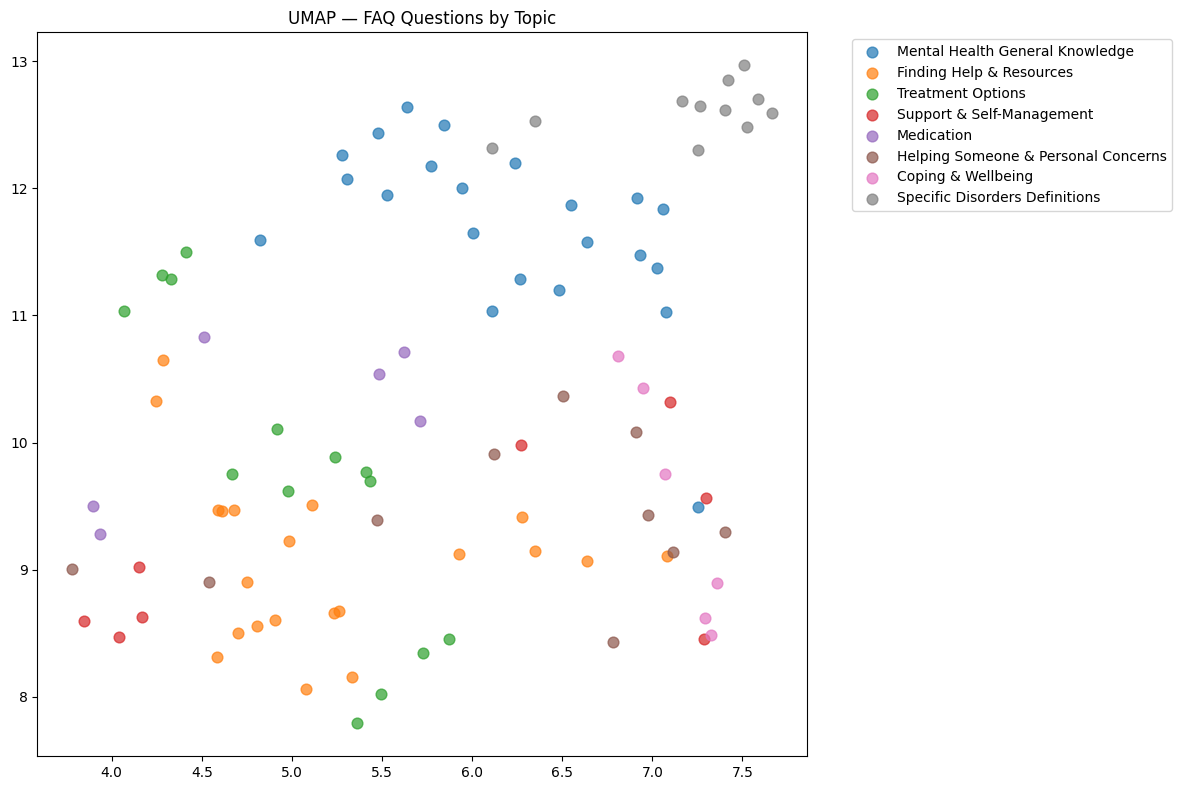

In [109]:
# 2D UMAP for visualization of clusters
!pip install umap-learn

import umap
import matplotlib.pyplot as plt

reducer = umap.UMAP(n_components=2, random_state=42) #reduce the 384-dimensional embeddings to 2D
embeddings_2d = reducer.fit_transform(embeddings)

plt.figure(figsize=(12, 8))
for topic in df['topic'].unique():
    mask = df['topic'] == topic
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1], 
                label=topic, alpha=0.7, s=60)

plt.title('UMAP — FAQ Questions by Topic')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

UMAP visualization shows significant overlap between clusters, with no clear separation between most topic groups. Only the "Specific Disorders Definitions" cluster appears relatively distinct from the others. This is expected given the small size of the dataset (98 questions).

For these reasons, we decided to not proceed with a classification procedure and only focus on the chatbot, which does not require well-separated clusters to work effectively. We will use a retrieval approach based on cosine similarity between Sentence-BERT embeddings, which should be robust enough to handle semantic similarity even with a small and overlapping dataset.

## Retrieval-Based Chatbot with Sentence-BERT

We now define the retrieval response function for the chatbot. Given a user input, it encodes the question, computes cosine similarity with all FAQ questions, and returns the most similar answer. If the best match score is below a given threshold, a fallback message is returned to avoid returning irrelevant answers.

In [110]:
from sklearn.metrics.pairwise import cosine_similarity

def get_response(user_input, threshold=0.54):
    # Encode the user input
    user_embedding = sbert.encode([user_input])
    user_embedding = normalize(user_embedding)

    # Compute cosine similarity with all FAQ questions
    similarities = cosine_similarity(user_embedding, embeddings_norm)[0]

    # Find the most similar question
    best_idx = similarities.argmax()
    best_score = similarities[best_idx]
    
    if best_score < threshold:
        return {
            'answer': "I'm sorry, I don't have enough info about this topic.",
            'matched_question': None,
            'score': best_score
        }
    
    return {
        'answer': df['Answers'].iloc[best_idx],
        'matched_question': df['Questions'].iloc[best_idx],
        'score': best_score
    }

In [111]:
print(get_response("What is happiness?")['answer'])
print(get_response("What is depression?")['answer'])

I'm sorry, I don't have enough info about this topic.
Sadness is a normal reaction to a loss, disappointment, problems, or other difficult situations. Feeling sad from time to time is just another part of being human. In these cases, feelings of sadness go away quickly and you can go about your daily life. 
 Other ways to talk about sadness might be ‘feeling low,’ ‘feeling down,’ or ‘feeling blue.’ A person may say they are feeling ‘depressed,’ but if it goes away on its own and doesn’t impact life in a big way, it probably isn’t the illness of depression. 
 Depression is a mental illness that affects your mood, the way you understand yourself, and the way you understand and relate to things around you. It can also go by different names, such as clinical depression, major depressive disorder, or major depression. Depression can come up for no reason, and it lasts for a long time. It’s much more than sadness or low mood. People who experience depression may feel worthless or hopeless. T

## Building the chatbot

We use the previous response function to finalize the chatbot. We personalize the first and last sentence of the conversation.

In [112]:
def chat():
    print("="*50)
    print("  Hi! I'm your Mental Health Chatbot. How can I help?")
    print("  (In case, just type 'quit' to exit.)")
    print("="*50)
    
    while True:
        user_input = input("\nYou: ").strip()
        if not user_input:
            continue
        if user_input.lower() in ['quit', 'exit']:
            print("Chatbot: Goodbye! Take care of yourself.")
            break
        
        result = get_response(user_input)
        print(f"\nChatbot: {result['answer']}")
        print(f"[Score: {result['score']:.3f}]")
        if result['matched_question']:
            print(f"[Matched: {result['matched_question']}]")

chat()

  Hi! I'm your Mental Health Chatbot. How can I help?
  (In case, just type 'quit' to exit.)



You:  How can I help a friend who is struggling with his mental health?



Chatbot: We naturally want to help a loved one who isn’t feeling well. How we can or should help may seem fairly obvious when a loved one experiences a physical health problem, but many people say they’re not sure how to best help when a loved one experiences a mental illness like depression. Here are some tips: 
 You don’t have to understand exactly what someone else is experiencing, you just need to recognize that it’s a difficult experience. You can try something like, “I can see that this experience or these symptoms are really painful for you,” or, “I’m sorry to hear that you’re feeling unwell.” If you have experienced depression yourself, you might say, “I know how you feel.” Just remember that everyone experiences illnesses like depression differently, and empathy is about recognizing the impact of the illness, not comparing symptoms. 
 You don’t have to be an expert, but learning more about depression can help you understand what’s going on (and maybe dispel some of the unhelp


You:  What's obesity?



Chatbot: I'm sorry, I don't have enough info about this topic.
[Score: 0.527]



You:  Do mental drugs cause addition?



Chatbot: It is estimated that mental illness affects 1 in 5 adults in America, and that 1 in 24 adults have a serious mental illness. Mental illness does not discriminate; it can affect anyone, regardless of gender, age, income, social status, ethnicity, religion, sexual orientation, or background. Although mental illness can affect anyone, certain conditions may be more common in different populations. For instance, eating disorders tend to occur more often in females, while disorders such as attention deficit/hyperactivity disorder is more prevalent in children. Additionally, all ages are susceptible, but the young and the old are especially vulnerable. Mental illnesses usually strike individuals in the prime of their lives, with 75 percent of mental health conditions developing by the age of 24. This makes identification and treatment of mental disorders particularly difficult, because the normal personality and behavioral changes of adolescence may mask symptoms of a mental health


You:  quit


Chatbot: Goodbye! Take care of yourself.


## Conclusion

In this project, we built a retrieval-based mental health FAQ chatbot using a BERT-style transformer model that encodes questions into dense semantic vectors.

Since the dataset had no predefined topic labels, we applied K-Means clustering on the Sentence-BERT embeddings to create 8 topic categories, which were then manually reviewed and adjusted. However, due to the small size of the dataset, the clusters showed significant overlap and the classification task was set aside.

The chatbot works by computing cosine similarity between the user input and all FAQ questions, returning the most relevant answer. A similarity threshold of 0.55 was set to avoid returning irrelevant responses.

- Limitations:
The dataset is very small (98 questions), which limits both the quality of the clusters and the chatbot’s coverage. \
The clusters overlap significantly, as confirmed by the UMAP visualization. \
The similarity threshold is a trade-off: a higher threshold filters irrelevant questions but may reject legitimate ones.

- Future improvements:
Add a generative component (e.g. fine-tuned GPT) to handle out-of-domain questions more naturally. \
Evaluate the chatbot formally with a ground truth test set and Hit Rate metrics.